**Name: Soham Khore<br>
PRN: 202401040267<br>
Roll No: 67<br>
Div/Batch: A/A3<br>
Subject: AIML<br>
Assignment 2: Feature Engineering<br>
Aim: To implement techniques of Feature Engineering to transforms raw data into informative features**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/diabetes.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:

print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0


In [ ]:

measurement_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in measurement_cols:
    print(f"{col}: {(df[col] == 0).sum()} zero values")


Glucose: 5 zero values
BloodPressure: 35 zero values
SkinThickness: 227 zero values
Insulin: 374 zero values
BMI: 11 zero values


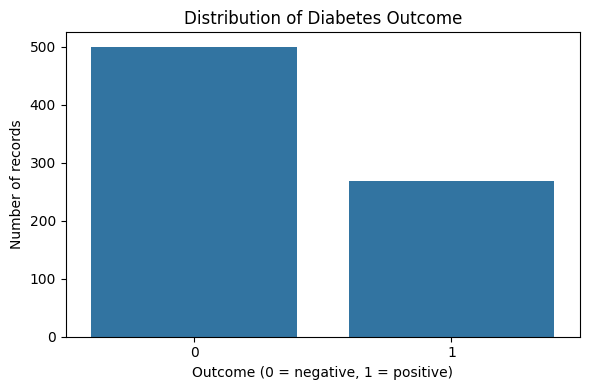

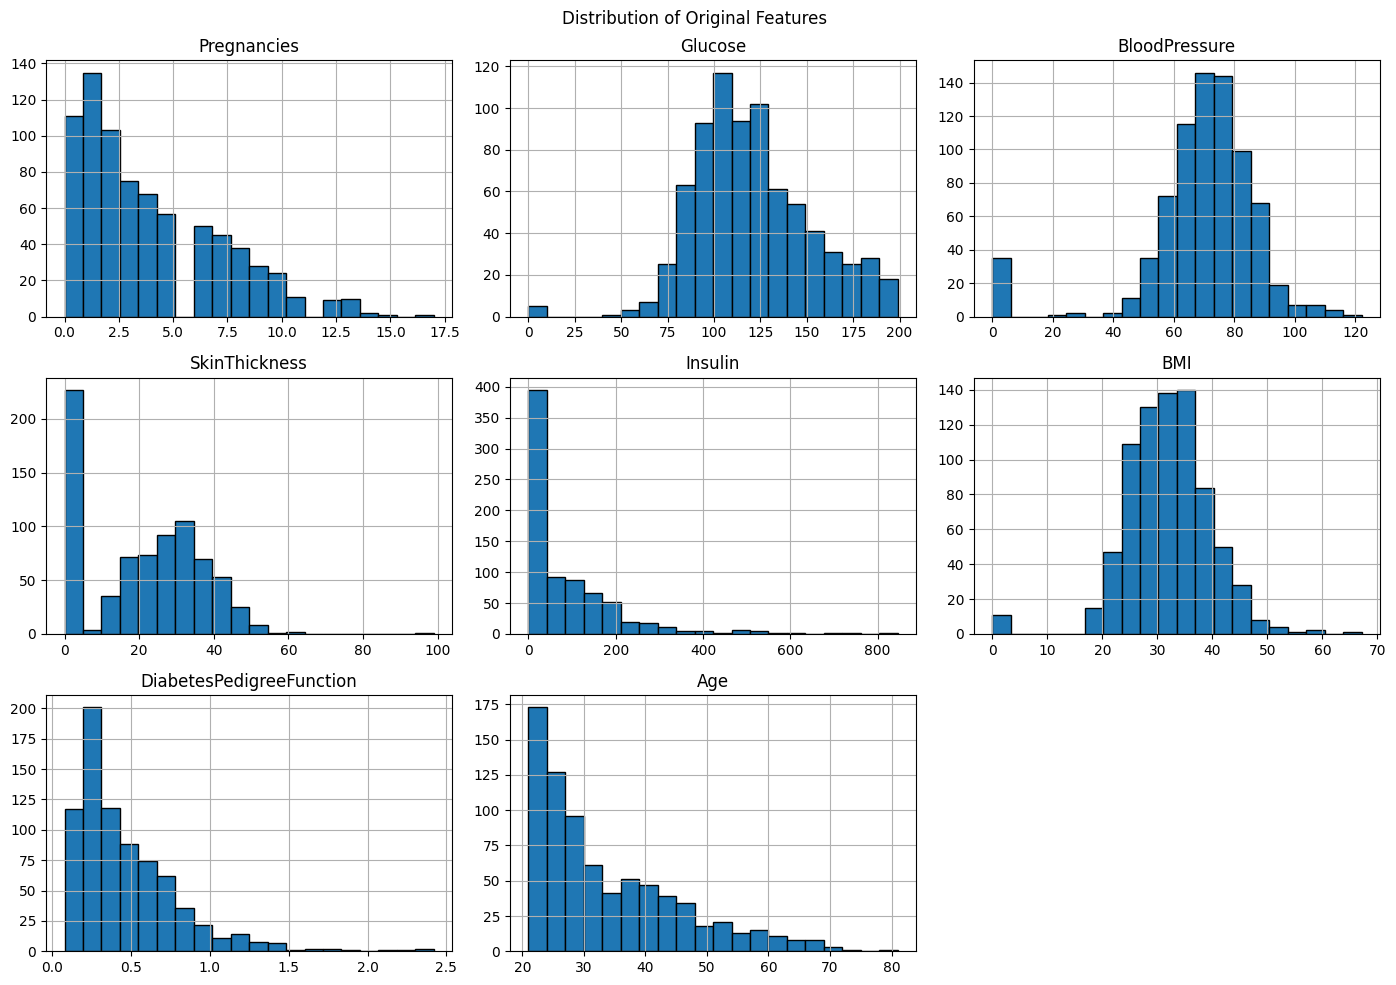

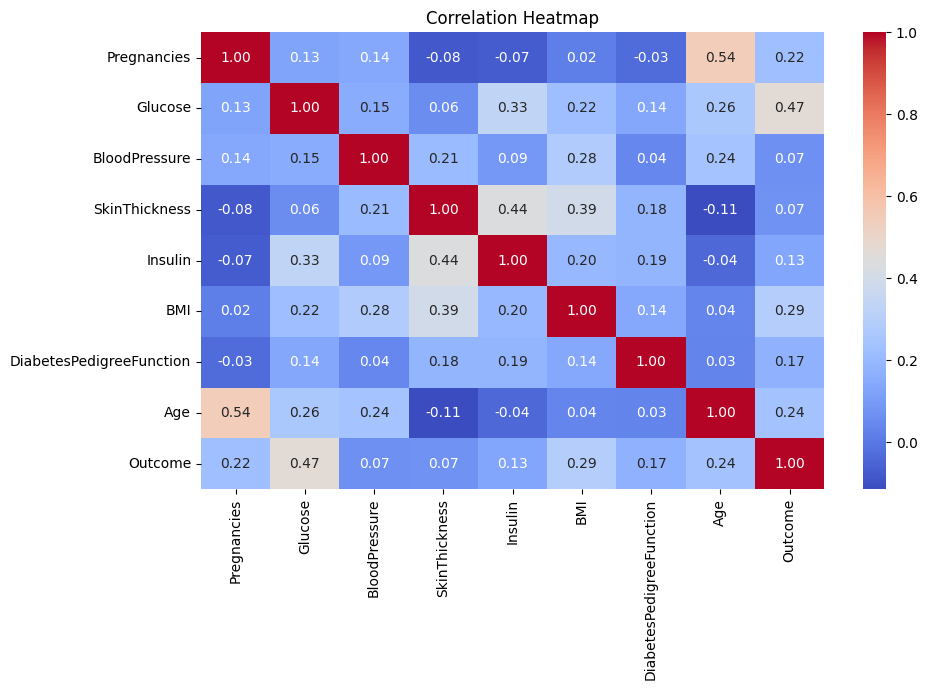

In [ ]:

# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = negative, 1 = positive)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# Feature distributions
df.drop(columns="Outcome").hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distribution of Original Features")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:

# Work on a copy of the original dataset
df_clean = df.copy()

# These measurements should not normally be zero
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zero-coded missing values with NaN
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)

print("Missing values after zero handling:")
display(df_clean.isnull().sum())

print("\nMissing percentage:")
display((df_clean.isnull().mean() * 100).round(2))


Missing values after zero handling:


,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Missing percentage:


,0
Pregnancies,0.00
Glucose,0.65
BloodPressure,4.56
SkinThickness,29.56
Insulin,48.70
BMI,1.43
DiabetesPedigreeFunction,0.00
Age,0.00
Outcome,0.00


In [ ]:

from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 614
Testing records: 154

Training target distribution:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Testing target distribution:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


In [ ]:

def engineer_features(data):
    data = data.copy()

    # Age-based groups
    data["AgeGroup"] = pd.cut(
        data["Age"],
        bins=[0, 30, 45, 60, np.inf],
        labels=["Young", "Adult", "Middle_Aged", "Senior"],
        right=False
    )

    # BMI categories for analytical comparison
    data["BMICategory"] = pd.cut(
        data["BMI"],
        bins=[-np.inf, 18.5, 25, 30, np.inf],
        labels=["Underweight", "Normal", "Overweight", "Obese"],
        right=False
    )

    # Interaction feature
    data["Glucose_BMI"] = data["Glucose"] * data["BMI"]

    # Log transformation; log1p handles zero values
    data["Insulin_Log"] = np.log1p(data["Insulin"])

    return data


X_train_eng = engineer_features(X_train)
X_test_eng = engineer_features(X_test)

print("Original feature count:", X_train.shape[1])
print("Engineered feature count:", X_train_eng.shape[1])

display(X_train_eng.head())


Original feature count: 8
Engineered feature count: 12


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,AgeGroup,BMICategory,Glucose_BMI,Insulin_Log
353,1,90.0,62.0,12.0,43.0,27.2,0.580,24,Young,Overweight,2448.0,3.784190
711,5,126.0,78.0,27.0,22.0,29.6,0.439,40,Adult,Overweight,3729.6,3.135494
373,2,105.0,58.0,40.0,94.0,34.9,0.225,25,Young,Obese,3664.5,4.553877
46,1,146.0,56.0,NaN,NaN,29.7,0.564,29,Young,Overweight,4336.2,NaN
682,0,95.0,64.0,39.0,105.0,44.6,0.366,22,Young,Obese,4237.0,4.663439


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor(data):
    categorical_cols = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    numerical_cols = data.select_dtypes(
        include=["number"]
    ).columns.tolist()

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    return preprocessor


baseline_preprocessor = make_preprocessor(X_train)
engineered_preprocessor = make_preprocessor(X_train_eng)

print("Preprocessing pipelines created successfully.")


Preprocessing pipelines created successfully.


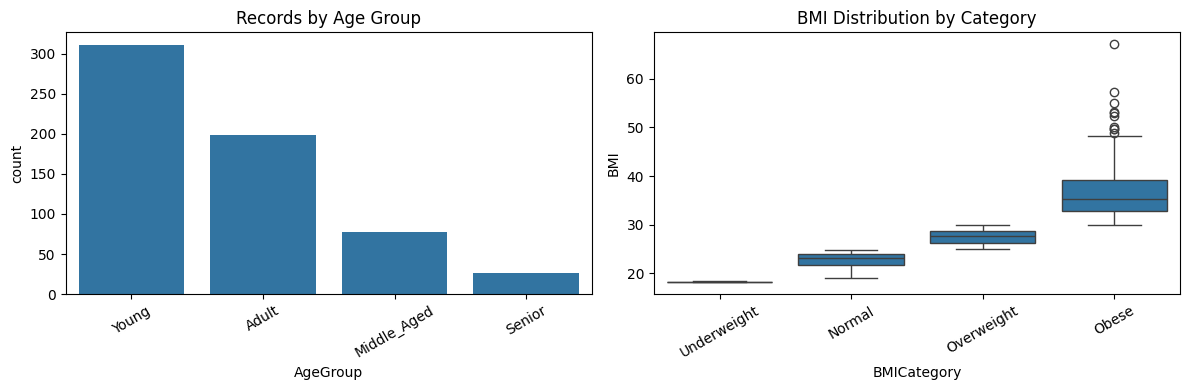

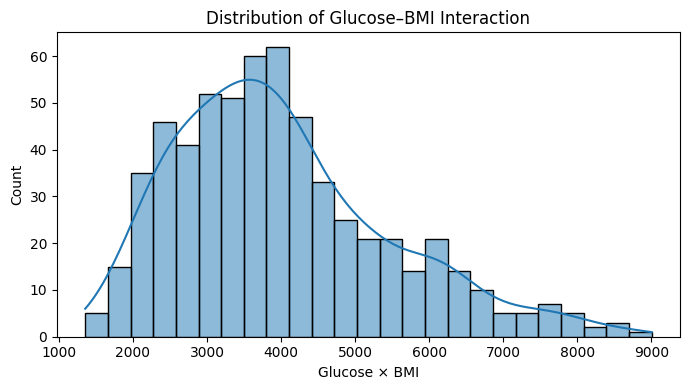

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=X_train_eng,
    x="AgeGroup",
    ax=axes[0]
)
axes[0].set_title("Records by Age Group")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=X_train_eng,
    x="BMICategory",
    y="BMI",
    ax=axes[1]
)
axes[1].set_title("BMI Distribution by Category")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(X_train_eng["Glucose_BMI"], bins=25, kde=True)
plt.title("Distribution of Glucose–BMI Interaction")
plt.xlabel("Glucose × BMI")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

baseline_model = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

engineered_model = Pipeline([
    ("preprocessor", engineered_preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

baseline_model.fit(X_train, y_train)
engineered_model.fit(X_train_eng, y_train)

baseline_pred = baseline_model.predict(X_test)
baseline_prob = baseline_model.predict_proba(X_test)[:, 1]

engineered_pred = engineered_model.predict(X_test_eng)
engineered_prob = engineered_model.predict_proba(X_test_eng)[:, 1]


def evaluate_model(name, y_true, pred, prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-score": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob)
    }


results = pd.DataFrame([
    evaluate_model(
        "Baseline", y_test, baseline_pred, baseline_prob
    ),
    evaluate_model(
        "Engineered", y_test, engineered_pred, engineered_prob
    )
])

display(results.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline,0.708,0.60,0.500,0.545,0.813
1,Engineered,0.727,0.63,0.537,0.580,0.836


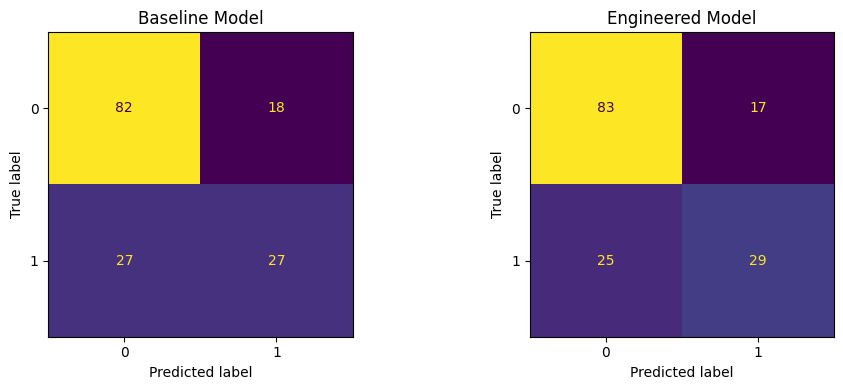

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_pred, ax=axes[0], colorbar=False
)
axes[0].set_title("Baseline Model")

ConfusionMatrixDisplay.from_predictions(
    y_test, engineered_pred, ax=axes[1], colorbar=False
)
axes[1].set_title("Engineered Model")

plt.tight_layout()
plt.show()


In [ ]:

final_data = engineer_features(df_clean)
final_data["Outcome"] = y

final_data.to_csv(
    "diabetes_engineered.csv",
    index=False
)

print("Saved diabetes_engineered.csv")
display(final_data.head())


Saved diabetes_engineered.csv


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,AgeGroup,BMICategory,Glucose_BMI,Insulin_Log
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1,Middle_Aged,Obese,4972.8,NaN
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0,Adult,Overweight,2261.0,NaN
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1,Adult,Normal,4263.9,NaN
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,Young,Overweight,2500.9,4.553877
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,Adult,Obese,5904.7,5.129899


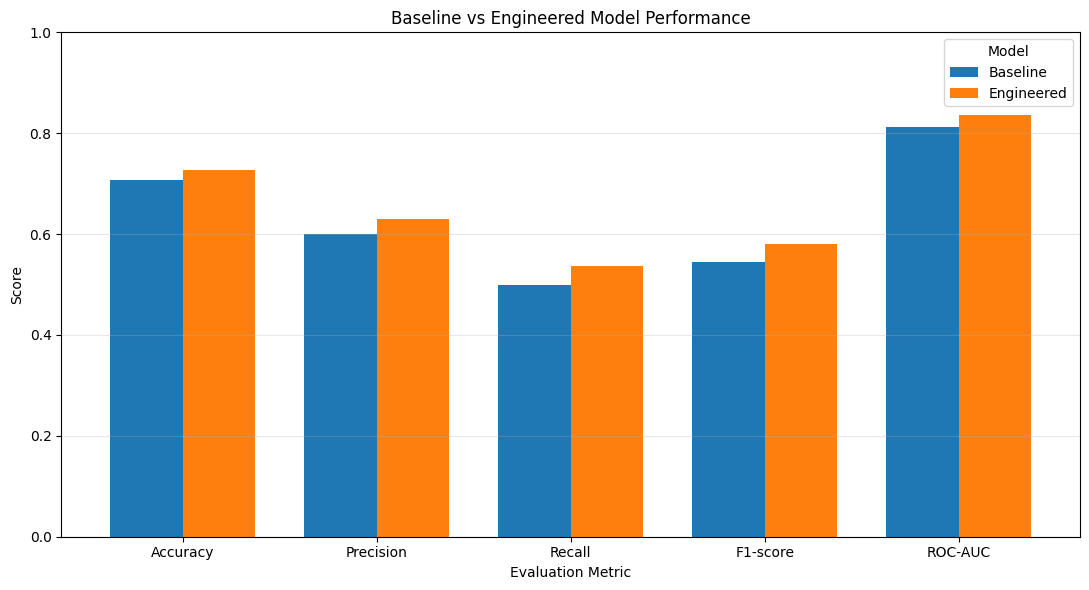

In [ ]:

# Compare baseline and engineered model performance

metrics = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]

comparison = results.set_index("Model")[metrics].T

ax = comparison.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Baseline vs Engineered Model Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
